# Customer Churn Prediction using Logistic Regression

**Course:** CSE3141 — Predictive Analytics
**Project Type:** Mini Project

## 1. Project Introduction

This notebook builds a machine learning model that predicts whether a telecom
customer is likely to **churn** (cancel their subscription) using
**Logistic Regression**.

The notebook is organized in stages that are built up incrementally:

1. Problem Definition (this stage)
2. Data Cleaning
3. Exploratory Data Analysis (EDA)
4. Logistic Regression Training
5. Model Validation and Hyperparameter Tuning

Each stage only contains the work relevant to that stage. Data loading,
cleaning, visualizations, and modeling are implemented in later stages so
that every number reported is based on the real dataset, never invented.

## 2. What is Customer Churn, and Why Does It Matter?

**Customer churn** means a customer stops using a company's service —
for example, a telecom subscriber cancelling their plan and switching to a
competitor.

### Why telecom companies care about churn

- Acquiring a brand-new customer is significantly more expensive (through
  advertising, promotional offers, and onboarding) than keeping an existing
  one.
- Even a small reduction in churn rate can have a large effect on long-term
  revenue, because the customer keeps paying every month instead of leaving.
- If a company can predict *in advance* which customers are at risk of
  leaving, it can take action early — for example, offering a loyalty
  discount, improving a specific service, or reaching out proactively —
  **before** the customer actually cancels.

This is exactly why churn prediction is a classic, high-value use case for
predictive analytics in the telecom industry.

## 3. Objectives and Expected Outcomes

### Business Objective
Identify which customers are at high risk of churning so the business can
prioritize retention efforts (offers, support outreach, service
improvements) towards those customers specifically, instead of treating
every customer the same way.

### Machine Learning Objective
Build a **binary classification** model that takes a customer's account
and service details as input and outputs:

- A **predicted class**: will the customer churn (`Yes`) or not (`No`)?
- A **churn probability**: a number between 0 and 1 representing how likely
  the model thinks that customer is to churn.

### Expected Outcome
A trained Logistic Regression model, evaluated using standard classification
metrics (accuracy, precision, recall, F1-score, ROC-AUC — all defined and
computed in Stage 5), along with an interactive demo app where a user can
enter a hypothetical customer's details and see the predicted churn risk.

No specific accuracy or performance number is claimed at this stage — those
will be reported honestly in Stage 5 once the model is actually trained and
evaluated on real data.

## 4. Dataset Description

This project uses the **Telco Customer Churn** dataset, a well-known public
dataset (originally published by IBM, widely distributed via Kaggle) used in
churn-modeling tutorials and research.

- **File:** `WA_Fn-UseC_-Telco-Customer-Churn.csv`
- **Rows:** 7,043 customers
- **Columns:** 21 (20 input/descriptive columns + 1 target column)

### All 21 Original Columns

| # | Column | Description |
|---|--------|--------------|
| 1 | `customerID` | Unique identifier for each customer (not predictive — dropped during cleaning) |
| 2 | `gender` | Customer's gender (`Male`/`Female`) — kept for descriptive analysis only, see Ethics section |
| 3 | `SeniorCitizen` | Whether the customer is a senior citizen (1) or not (0) |
| 4 | `Partner` | Whether the customer has a partner (`Yes`/`No`) |
| 5 | `Dependents` | Whether the customer has dependents (`Yes`/`No`) |
| 6 | `tenure` | Number of months the customer has stayed with the company |
| 7 | `PhoneService` | Whether the customer has phone service (`Yes`/`No`) |
| 8 | `MultipleLines` | Whether the customer has multiple phone lines (`Yes`/`No`/`No phone service`) |
| 9 | `InternetService` | Type of internet service (`DSL`/`Fiber optic`/`No`) |
| 10 | `OnlineSecurity` | Whether the customer has online security add-on (`Yes`/`No`/`No internet service`) |
| 11 | `OnlineBackup` | Whether the customer has online backup add-on (`Yes`/`No`/`No internet service`) |
| 12 | `DeviceProtection` | Whether the customer has device protection add-on (`Yes`/`No`/`No internet service`) |
| 13 | `TechSupport` | Whether the customer has tech support add-on (`Yes`/`No`/`No internet service`) |
| 14 | `StreamingTV` | Whether the customer has streaming TV (`Yes`/`No`/`No internet service`) |
| 15 | `StreamingMovies` | Whether the customer has streaming movies (`Yes`/`No`/`No internet service`) |
| 16 | `Contract` | Contract term (`Month-to-month`/`One year`/`Two year`) |
| 17 | `PaperlessBilling` | Whether the customer uses paperless billing (`Yes`/`No`) |
| 18 | `PaymentMethod` | How the customer pays (`Electronic check`/`Mailed check`/`Bank transfer (automatic)`/`Credit card (automatic)`) |
| 19 | `MonthlyCharges` | Current monthly charge amount (numeric) |
| 20 | `TotalCharges` | Total amount charged to the customer over their tenure (numeric, stored as text in the raw file) |
| 21 | `Churn` | **Target variable** — whether the customer churned (`Yes`/`No`) |

A detailed inspection of actual row counts, data types, and missing values
is performed in Stage 2 (Data Cleaning), where the real numbers from the
dataset are reported rather than assumed here.

## 5. Input Features vs. Target Variable

In a supervised machine learning problem, every row is split conceptually
into:

- **Input features (X):** the columns the model is allowed to look at to
  make a prediction. Here, that is all columns *except* `customerID` (just
  an identifier, not predictive) and `Churn` (the thing we are trying to
  predict).
- **Target variable (y):** the column we want the model to predict. Here,
  that is `Churn`, which takes the value `Yes` or `No`. Because there are
  exactly two possible outcomes, this is a **binary classification**
  problem.

During preprocessing (Stage 2), categorical input features (like
`Contract` or `PaymentMethod`) are converted into a numeric form the model
can use, and numeric features (like `MonthlyCharges`) are scaled — but the
*conceptual* split between "inputs" and "target" is decided here, in the
problem definition.

## 6. Ethical Considerations

Machine learning models can unintentionally encode unfair bias if they are
trained on sensitive attributes. This dataset includes `gender`, which is
useful for *descriptive* analysis (for example, checking whether churn rate
differs noticeably between groups), but:

> **Gender must not be used as an input feature for the predictive model or
> for any customer retention decision.**

**Why this matters:**

- Using gender to decide who receives a retention offer (or who is denied
  one) would be a form of discriminatory decision-making, regardless of
  whether the model's statistical performance improves.
- A good churn-prediction system should base its decisions on
  *behavior and account attributes* (tenure, contract type, charges,
  services used) — not on demographic attributes a customer cannot control
  and that have no legitimate causal link to deserving better service.

**How this is enforced in this project:** `gender` is explored in the EDA
stage purely for descriptive insight, but it is **excluded from the feature
set** used to train the Logistic Regression model in Stage 4 onward.

### Other limitations to keep in mind
- This is a single, static snapshot of customer data — it does not capture
  trends over time or events after the data was collected.
- The model reflects patterns in *this specific* telecom provider's
  customer base and may not generalize to a different company without
  retraining.

## 7. Why Logistic Regression for This Problem?

**Logistic Regression** is a statistical model used for **binary
classification** — predicting one of two possible outcomes (here, `Churn`
= `Yes` or `No`).

It is a strong first choice for this problem for several reasons:

1. **Matches the problem type.** Logistic Regression is specifically
   designed to model the probability of a binary outcome, using the
   **sigmoid function** to squeeze any numeric input into a value between
   0 and 1 — which is exactly the "churn probability" this project needs to
   produce.
2. **Interpretability.** Each input feature gets a **coefficient**. The
   sign and size of a coefficient directly show whether that feature
   increases or decreases churn risk, and by how much (via **odds
   ratios**, covered in Stage 4). This matters for a business: it's not
   enough to know *who* will churn, decision-makers also want to know
   *why*, so they can act on it.
3. **Good baseline for tabular data.** With a mix of categorical and
   numeric features like this dataset has, Logistic Regression is a
   well-understood, fast-to-train baseline that is standard practice before
   trying more complex models.
4. **Handles class imbalance with simple tools.** The dataset has more
   non-churners than churners (confirmed with real counts in Stage 2).
   Logistic Regression supports a `class_weight="balanced"` setting (used
   in Stage 4) that adjusts for this imbalance without needing to modify
   the dataset itself.

This project also trains a **Linear Discriminant Analysis (LDA)** model in
Stage 5 purely as a comparison baseline, to check whether Logistic
Regression's performance is actually competitive on this dataset.

In [1]:
# ---------------------------------------------------------------
# Initial setup: import the libraries used throughout this notebook.
# No dataset is loaded here — loading and cleaning the data is the
# subject of Stage 2 (Data Cleaning), kept in a separate section so
# each stage stays focused on one part of the project.
# ---------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split

# Display settings: show all columns when printing a DataFrame
pd.set_option("display.max_columns", None)

print("Setup complete. Libraries imported successfully.")

Setup complete. Libraries imported successfully.


## 8. Stage 2 — Data Cleaning and Preprocessing

This section loads the real dataset, inspects it, and cleans it using the
reusable functions defined in `src/preprocess.py`. No statistics in this
section are invented — every number below is the actual output of running
these cells against `data/WA_Fn-UseC_-Telco-Customer-Churn.csv`.

In [2]:
import sys
sys.path.insert(0, "..")

from src.preprocess import (
    load_data,
    inspect_data,
    remove_duplicates,
    convert_total_charges,
    handle_missing_total_charges,
    drop_customer_id,
    detect_outliers_iqr,
    plot_boxplots,
    identify_feature_types,
    build_preprocessing_pipeline,
)

DATA_PATH = "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"

raw_df = load_data(DATA_PATH)
raw_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 8.1 Initial Inspection

`inspect_data()` reports the dataset's shape, column data types, missing
values, duplicate rows, and the Churn distribution — all computed directly
from the loaded CSV.

In [3]:
summary = inspect_data(raw_df)

print("Rows:", summary["n_rows"])
print("Columns:", summary["n_columns"])
print()
print("Data types:")
for col, dtype in summary["dtypes"].items():
    print(f"  {col}: {dtype}")
print()
print("Missing values (NaN) per column:")
print({k: v for k, v in summary["missing_per_column"].items() if v > 0} or "None")
print()
print("Duplicate rows:", summary["duplicate_rows"])
print()
print("Churn distribution:", summary["churn_counts"])

Rows: 7043
Columns: 21

Data types:
  customerID: object
  gender: object
  SeniorCitizen: int64
  Partner: object
  Dependents: object
  tenure: int64
  PhoneService: object
  MultipleLines: object
  InternetService: object
  OnlineSecurity: object
  OnlineBackup: object
  DeviceProtection: object
  TechSupport: object
  StreamingTV: object
  StreamingMovies: object
  Contract: object
  PaperlessBilling: object
  PaymentMethod: object
  MonthlyCharges: float64
  TotalCharges: object
  Churn: object

Missing values (NaN) per column:
None

Duplicate rows: 0

Churn distribution: {'No': 5174, 'Yes': 1869}


**Insight:** The dataset has 7,043 rows and 21 columns, no fully
duplicate rows, and no `NaN` values reported by pandas directly — but as
the next step shows, `TotalCharges` hides 11 blank-string values that
`isnull()` does not catch because they are not technically `NaN` until
converted to numeric. The target `Churn` is imbalanced: far more customers
did **not** churn (`No`) than did (`Yes`), which is why
`class_weight="balanced"` will matter later in Stage 4.

### 8.2 Duplicate Records

`remove_duplicates()` drops any fully duplicate rows (every column
identical). Since the inspection above already reported 0 duplicate rows,
this step changes nothing for this dataset, but it is still included as a
defensive, reusable cleaning step.

In [4]:
deduped_df = remove_duplicates(raw_df)
print("Shape before:", raw_df.shape, "| Shape after:", deduped_df.shape)

Shape before: (7043, 21) | Shape after: (7043, 21)


### 8.3 Converting TotalCharges to Numeric

`TotalCharges` is stored as **text** in the raw CSV (note the `object`
dtype above), even though it is a monetary amount. `convert_total_charges()`
uses `pd.to_numeric(..., errors="coerce")`, which turns any value that
cannot be parsed as a number (the 11 blank strings) into `NaN`, making them
explicit and detectable instead of silently hiding inside a text column.

In [5]:
converted_df = convert_total_charges(deduped_df)
n_missing = converted_df["TotalCharges"].isnull().sum()
print("TotalCharges dtype after conversion:", converted_df["TotalCharges"].dtype)
print("Missing TotalCharges values after conversion:", n_missing)

TotalCharges dtype after conversion: float64
Missing TotalCharges values after conversion: 11


### 8.4 Investigating and Handling the Missing TotalCharges Values

Before blindly filling the 11 missing values, we inspect *who* they belong
to.

In [6]:
missing_rows = converted_df[converted_df["TotalCharges"].isnull()]
missing_rows[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


**Finding:** All 11 rows with a missing `TotalCharges` have
`tenure == 0` — these are brand-new customers who have not yet completed a
single billing cycle. A `TotalCharges` of 0 is therefore the logically
correct value for them, not a guess. `handle_missing_total_charges()`
verifies this condition (tenure == 0 for every missing row) before filling,
and would raise an error instead of filling if any missing row had
non-zero tenure — so this fill is never applied blindly.

In [7]:
cleaned_df = handle_missing_total_charges(converted_df)
print("Missing TotalCharges values after filling:", cleaned_df["TotalCharges"].isnull().sum())
cleaned_df.loc[missing_rows.index, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Missing TotalCharges values after filling: 0


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,0.0,No
753,0,20.25,0.0,No
936,0,80.85,0.0,No
1082,0,25.75,0.0,No
1340,0,56.05,0.0,No
3331,0,19.85,0.0,No
3826,0,25.35,0.0,No
4380,0,20.00,0.0,No
5218,0,19.70,0.0,No
6670,0,73.35,0.0,No


### 8.5 Removing customerID

`customerID` uniquely identifies each row and has no relationship with
whether a customer churns — keeping it as a feature would just add noise
(or let the model "memorize" training rows instead of learning general
patterns). `drop_customer_id()` removes it.

In [8]:
cleaned_df = drop_customer_id(cleaned_df)
print("Columns after dropping customerID:", cleaned_df.shape[1])
print("'customerID' in columns:", "customerID" in cleaned_df.columns)

Columns after dropping customerID: 20
'customerID' in columns: False


### 8.6 Outlier Investigation Using the IQR Method

The **IQR (Interquartile Range)** method flags a value as a statistical
outlier if it falls more than 1.5×IQR below the 25th percentile (Q1) or
above the 75th percentile (Q3). This is computed — not assumed — for each
numeric column below, and outliers are only **reported**, never
automatically removed, since an "outlier" here (e.g. a customer with very
high tenure) can be a perfectly real, valid customer rather than a data
error.

In [9]:
numeric_cols_to_check = ["tenure", "MonthlyCharges", "TotalCharges"]
outlier_report = detect_outliers_iqr(cleaned_df, numeric_cols_to_check)

for col, stats in outlier_report.items():
    print(f"--- {col} ---")
    print(f"  Q1={stats['Q1']:.2f}, Q3={stats['Q3']:.2f}, IQR={stats['IQR']:.2f}")
    print(f"  Bounds: [{stats['lower_bound']:.2f}, {stats['upper_bound']:.2f}]")
    print(f"  Outliers found: {stats['outlier_count']}")

--- tenure ---
  Q1=9.00, Q3=55.00, IQR=46.00
  Bounds: [-60.00, 124.00]
  Outliers found: 0
--- MonthlyCharges ---
  Q1=35.50, Q3=89.85, IQR=54.35
  Bounds: [-46.02, 171.38]
  Outliers found: 0
--- TotalCharges ---
  Q1=398.55, Q3=3786.60, IQR=3388.05
  Bounds: [-4683.52, 8868.67]
  Outliers found: 0


**Insight:** None of the three numeric columns (`tenure`,
`MonthlyCharges`, `TotalCharges`) contain any IQR outliers in this dataset
— every value falls within the computed bounds. This is a genuine result
of running the IQR calculation on the real data, not an assumption; it
means no rows need to be removed or capped for these columns.

### 8.7 Box Plots

Box plots visualize the same Q1/Q3/IQR statistics computed above: the box
spans Q1 to Q3, the line inside is the median, and the whiskers extend to
the IQR bounds. Each plot is saved as a PNG to `reports/figures/`.

In [10]:
saved_paths = plot_boxplots(cleaned_df, numeric_cols_to_check, output_dir="../reports/figures")
print("Saved plots:")
for p in saved_paths:
    print(" -", p)

Saved plots:
 - ../reports/figures\boxplot_tenure.png
 - ../reports/figures\boxplot_MonthlyCharges.png
 - ../reports/figures\boxplot_TotalCharges.png


**Insight:** The box plots visually confirm the IQR calculation above
— no points appear beyond the whiskers for any of the three columns, which
matches the 0-outlier result found numerically.

### 8.8 Identifying Categorical and Numerical Features

`identify_feature_types()` splits the cleaned dataframe's columns into
categorical and numerical feature lists, ready for the preprocessing
pipeline. **`gender` is deliberately excluded** from both lists by
default, for the ethical reason stated in Section 6: it must not be used
as a predictive input or influence any retention decision. `Churn` (the
target) is also excluded, since it is the label, not a feature.

In [11]:
categorical_cols, numerical_cols = identify_feature_types(cleaned_df)

print("Categorical feature columns:", categorical_cols)
print()
print("Numerical feature columns:", numerical_cols)
print()
print("'gender' excluded from features:", "gender" not in categorical_cols and "gender" not in numerical_cols)

Categorical feature columns: ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical feature columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

'gender' excluded from features: True


### 8.9 Building the Preprocessing Pipeline (Not Fitted Here)

`build_preprocessing_pipeline()` returns a scikit-learn `ColumnTransformer`
that will:

- **One-hot encode** the categorical columns — turning a column like
  `Contract` (`Month-to-month`/`One year`/`Two year`) into multiple binary
  (0/1) columns, since Logistic Regression needs numeric input and has no
  natural way to interpret category text. `handle_unknown="ignore"` means
  that if a category never seen during training appears later (e.g. a new
  `PaymentMethod`), it is encoded as all zeros instead of crashing.
- **Standard-scale** the numerical columns — transforming each one to have
  mean 0 and standard deviation 1, so that columns on very different
  scales (e.g. `tenure` in months vs. `TotalCharges` in currency) contribute
  more comparably to the model instead of the larger-magnitude column
  dominating just because of its units.

**This pipeline is intentionally left UNFITTED here.** Fitting a scaler or
encoder on the entire dataset before splitting into train/test would leak
information about the test set into training (the scaler would "see"
test-set values when computing its mean/std). The pipeline below is only
constructed now; it will be `.fit()` on the training split only in Stage 4,
then reused with `.transform()` on the test split and any new customer
data.

In [12]:
preprocessor = build_preprocessing_pipeline(categorical_cols, numerical_cols)
preprocessor

ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Partner', 'Dependents', 'PhoneService',
                                  'MultipleLines', 'InternetService',
                                  'OnlineSecurity', 'OnlineBackup',
                                  'DeviceProtection', 'TechSupport',
                                  'StreamingTV', 'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod']),
                                ('numerical', StandardScaler(),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges'])])

**Summary of Stage 2:** the dataset has been loaded, inspected,
deduplicated (no duplicates found), had `TotalCharges` converted to a
proper numeric type with its 11 missing values filled based on verified
zero-tenure status, had the non-predictive `customerID` dropped, been
checked for outliers (none found) with box plots saved for the report, and
had its features split into categorical/numerical lists with `gender`
excluded. An unfitted preprocessing pipeline is ready to be fitted on the
training data in Stage 4.

## 9. Exploratory Data Analysis

This section visualizes the cleaned dataset to understand *what* patterns
exist before building a predictive model in Stage 4. Every chart below is
generated directly from `data/WA_Fn-UseC_-Telco-Customer-Churn.csv` via the
`clean_dataset()` function from Stage 2 — no numbers here are invented.

`gender` is examined only if it comes up descriptively; it is never used as
a predictive feature or to drive any retention decision (see Section 6).

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from src.preprocess import clean_dataset

eda_df = clean_dataset(DATA_PATH)
eda_df["Churn_binary"] = (eda_df["Churn"] == "Yes").astype(int)
eda_df.shape

(7043, 21)

### 9.1 Key Statistics

Before charting, we compute the actual summary numbers referenced in the
interpretations below.

In [14]:
total_customers = len(eda_df)
churn_counts = eda_df["Churn"].value_counts()
churn_pct = eda_df["Churn"].value_counts(normalize=True) * 100

overall_churn_rate = churn_pct["Yes"]

avg_tenure_by_churn = eda_df.groupby("Churn")["tenure"].mean()
avg_monthly_by_churn = eda_df.groupby("Churn")["MonthlyCharges"].mean()
churn_rate_by_contract = eda_df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean() * 100)

print(f"Total customers: {total_customers}")
print(f"Churned: {churn_counts['Yes']} ({churn_pct['Yes']:.2f}%)")
print(f"Retained: {churn_counts['No']} ({churn_pct['No']:.2f}%)")
print(f"Overall churn rate: {overall_churn_rate:.2f}%")
print()
print("Average tenure (months) by churn status:")
print(avg_tenure_by_churn.round(2))
print()
print("Average MonthlyCharges by churn status:")
print(avg_monthly_by_churn.round(2))
print()
print("Churn rate (%) by contract type:")
print(churn_rate_by_contract.round(2))

Total customers: 7043


Churned: 1869 (26.54%)
Retained: 5174 (73.46%)
Overall churn rate: 26.54%

Average tenure (months) by churn status:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

Average MonthlyCharges by churn status:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

Churn rate (%) by contract type:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


### 9.2 Chart 1 — Overall Churn Distribution (Pie Chart)

A pie chart is a natural fit here because we are showing how a single
whole (all 7,043 customers) splits into two mutually exclusive parts
(churned vs. retained) — exactly the kind of "parts of a whole" comparison
pie charts communicate well, and with only two categories it stays easy to
read (pie charts become harder to interpret with many slices).

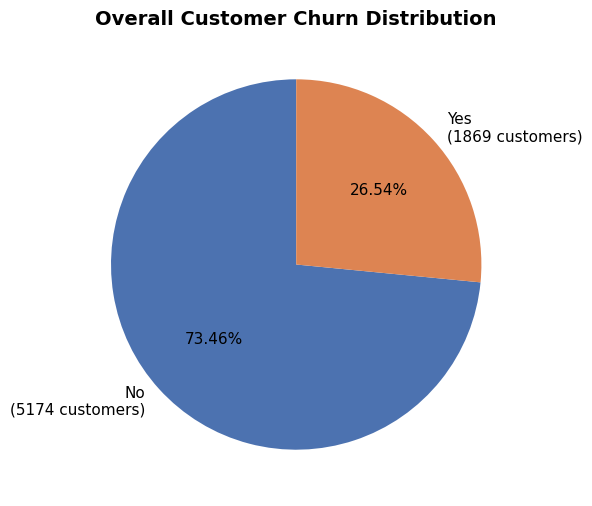

In [15]:
fig, ax = plt.subplots(figsize=(6, 6))
colors = ["#4C72B0", "#DD8452"]
ax.pie(
    churn_counts.values,
    labels=[f"{label}\n({count} customers)" for label, count in churn_counts.items()],
    autopct="%1.2f%%",
    colors=colors,
    startangle=90,
    textprops={"fontsize": 11},
)
ax.set_title("Overall Customer Churn Distribution", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig("../reports/figures/churn_distribution_pie.png", dpi=300)
plt.show()

**Interpretation:** Of 7,043 customers, 1869 churned (26.54%) and 5174 were retained (73.46%). The dataset is noticeably imbalanced toward retained customers — this is exactly why Stage 4 uses `class_weight="balanced"` when training Logistic Regression, so the model does not simply learn to always predict "No churn".

### 9.3 Chart 2 — Churn Rate by Contract Type (Bar Chart)

A bar chart is well suited for comparing a rate across a small number of
named categories. Critically, this chart plots the **percentage of
customers who churned within each contract type** (not raw counts), so
that contract types with different customer counts can be compared fairly
on equal footing.

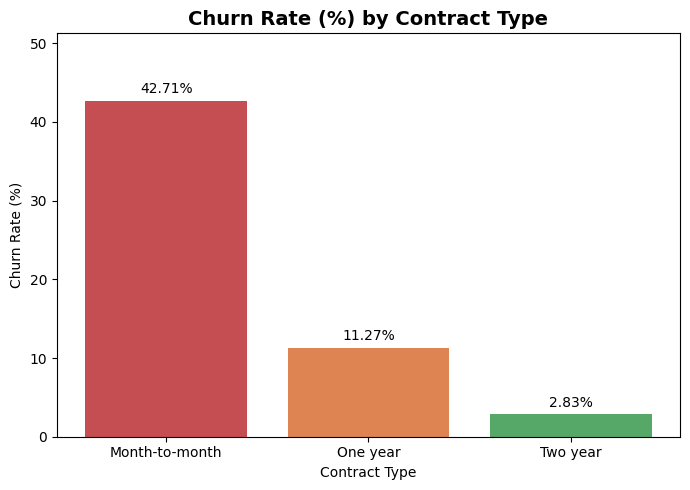

In [16]:
contract_order = ["Month-to-month", "One year", "Two year"]
churn_rate_ordered = churn_rate_by_contract.reindex(contract_order)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(churn_rate_ordered.index, churn_rate_ordered.values, color=["#C44E52", "#DD8452", "#55A868"])
ax.set_title("Churn Rate (%) by Contract Type", fontsize=14, fontweight="bold")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, max(churn_rate_ordered.values) * 1.2)

for bar, value in zip(bars, churn_rate_ordered.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 1, f"{value:.2f}%", ha="center", fontsize=10)

fig.tight_layout()
fig.savefig("../reports/figures/churn_rate_by_contract.png", dpi=300)
plt.show()

**Interpretation:** Churn rate drops sharply as contract length
increases — Month-to-month customers churn at 42.71%, compared to
11.27% for One-year and only 2.83% for Two-year contracts.
Customers with no long-term commitment are far more likely to leave,
suggesting contract length (or whatever makes a customer choose a longer
contract, such as higher satisfaction or price lock-in) is one of the
strongest behavioral signals of churn risk in this dataset.

### 9.4 Chart 3 — Tenure Distribution (Histogram)

A histogram shows how a single numeric variable (`tenure`, in months) is
distributed across all customers by grouping values into bins and counting
how many customers fall in each bin.

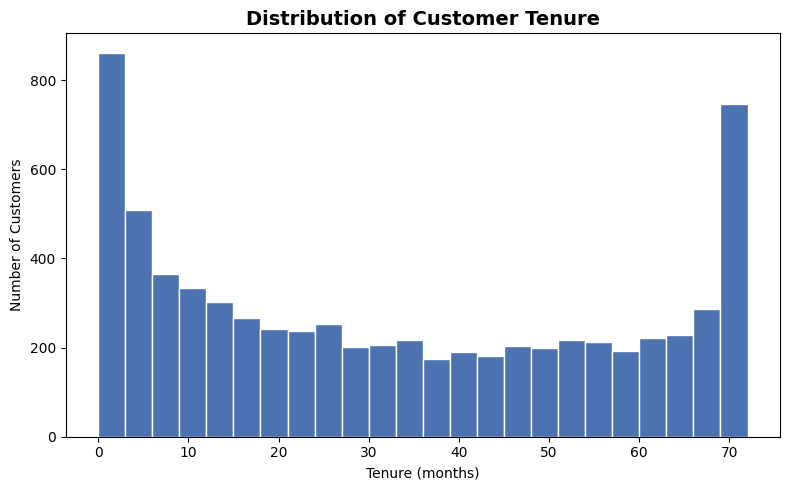

Tenure summary statistics:
count    7043.00
mean       32.37
std        24.56
min         0.00
25%         9.00
50%        29.00
75%        55.00
max        72.00
Name: tenure, dtype: float64


In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(eda_df["tenure"], bins=24, color="#4C72B0", edgecolor="white")
ax.set_title("Distribution of Customer Tenure", fontsize=14, fontweight="bold")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Number of Customers")
fig.tight_layout()
fig.savefig("../reports/figures/tenure_distribution.png", dpi=300)
plt.show()

print("Tenure summary statistics:")
print(eda_df["tenure"].describe().round(2))

**Interpretation:** Tenure ranges from 0 to 72 months with a mean of
about 32.4 months. The distribution is not a smooth bell curve — there are
noticeably large groups of customers at the very low end (near 0 months,
i.e. recently joined) and the very high end (near 72 months, i.e.
long-term loyal customers), with fewer customers in the middle. This
matches the contract-type finding above: many customers either leave early
or stay for the long haul, with fewer "in-between" cases.

### 9.5 Chart 4 — Correlation Heatmap

A **correlation heatmap** visualizes the **correlation coefficient**
between every pair of numeric columns at once, using color intensity.

- The correlation coefficient ranges from **-1 to +1**.
- A **positive correlation** (closer to +1) means as one variable
  increases, the other tends to increase too.
- A **negative correlation** (closer to -1) means as one variable
  increases, the other tends to decrease.
- A value near **0** means little to no linear relationship.

`Churn_binary` (1 = churned, 0 = retained) is included here purely to see
which numeric features move together with churn — `customerID` is
excluded (not numeric/predictive) and `gender` is excluded (ethical
requirement: never used as a predictive feature).

**Correlation does not prove causation:** two variables can correlate
strongly without one causing the other — there could be a third factor
driving both, or the relationship could be coincidental in this particular
dataset. For example, `tenure` and `TotalCharges` correlate strongly
simply because `TotalCharges` accumulates over time — it doesn't mean
tenure "causes" higher charges in a business sense, it's a direct
mathematical consequence of billing every month.

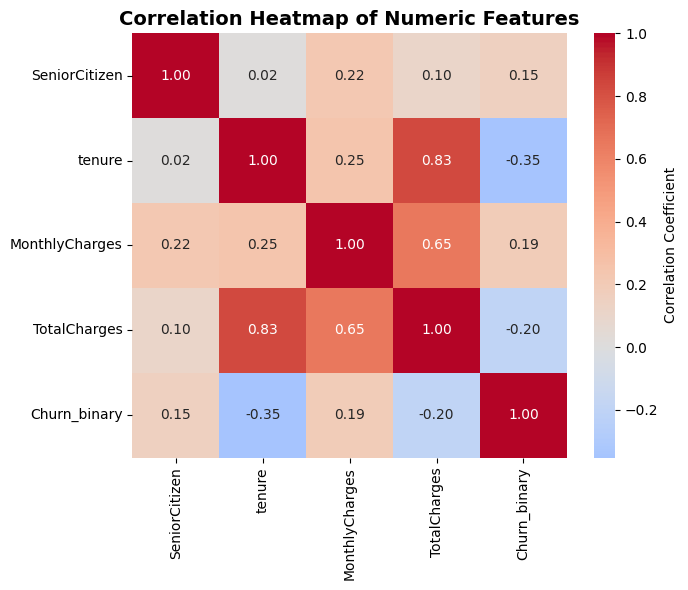

                SeniorCitizen  tenure  MonthlyCharges  TotalCharges  \
SeniorCitizen           1.000   0.017           0.220         0.103   
tenure                  0.017   1.000           0.248         0.826   
MonthlyCharges          0.220   0.248           1.000         0.651   
TotalCharges            0.103   0.826           0.651         1.000   
Churn_binary            0.151  -0.352           0.193        -0.198   

                Churn_binary  
SeniorCitizen          0.151  
tenure                -0.352  
MonthlyCharges         0.193  
TotalCharges          -0.198  
Churn_binary           1.000  


In [18]:
numeric_cols_for_corr = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "Churn_binary"]
corr_matrix = eda_df[numeric_cols_for_corr].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax,
            cbar_kws={"label": "Correlation Coefficient"})
ax.set_title("Correlation Heatmap of Numeric Features", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig("../reports/figures/correlation_heatmap.png", dpi=300)
plt.show()

print(corr_matrix.round(3))

**Interpretation:** `tenure` has the strongest relationship with churn
among these numeric features, at **-0.35** (negative) — longer-tenured
customers churn less. `MonthlyCharges` correlates **+0.19** (positive)
with churn — customers paying more per month churn somewhat more often.
`TotalCharges` correlates **-0.20** with churn, and `tenure`/`TotalCharges`
correlate strongly with each other at **+0.83**, which is expected since
`TotalCharges` is built from billing a customer every month of their
tenure — a mechanical relationship, not evidence that one factor
"causes" the other in a business sense.

### 9.6 Summary of Stage 3 Findings

- Overall churn rate: **26.54%** (1,869 of 7,043 customers).
- Churn is heavily concentrated in **Month-to-month** contracts
  (**42.71%** churn rate) versus One-year (**11.27%**) and Two-year
  (**2.83%**).
- Churned customers have a much lower average tenure (**~18.0 months**)
  than retained customers (**~37.6 months**).
- Churned customers pay a *higher* average monthly charge (**~$74.44**)
  than retained customers (**~$61.27**).
- `tenure` is the numeric feature most correlated with churn (**-0.35**),
  followed by `MonthlyCharges` (**+0.19**).

All of these numbers come directly from the cells above — no figure in
this summary was decided in advance.

## 10. Logistic Regression Model Building

This section trains the first predictive model: a Logistic Regression
classifier for churn. All functions used here are defined in
`src/train.py`, which reuses the Stage 2 preprocessing from
`src/preprocess.py` rather than duplicating it.

### 10.1 Train-Test Split

An **80/20 stratified split** separates the cleaned data into a training
set (used to fit the model) and a held-out test set (used only to
evaluate it afterward, never seen during training).

**Why stratification matters here:** this dataset is imbalanced
(~26.5% churn, ~73.5% no-churn, confirmed in Stage 3). A plain random
split could, by chance, place proportionally too few or too many churners
in the test set, making evaluation metrics — especially recall — noisy
and unreliable. `stratify=y` forces both the training and test sets to
preserve the same ~26.5% churn ratio as the full dataset, so the test set
is a fair, representative sample. `random_state=42` is fixed so the exact
same split is reproduced every time this notebook runs.

In [19]:
from src.train import (
    load_and_clean_data,
    prepare_features_and_target,
    split_data,
    build_model_pipeline,
    train_model,
    get_predictions,
    get_feature_names,
    get_coefficients_and_odds_ratios,
    save_model,
)

model_df = load_and_clean_data(DATA_PATH)
X, y = prepare_features_and_target(model_df)

print("Feature columns used for modeling:", list(X.columns))
print("'gender' in features:", "gender" in X.columns)
print("'customerID' in features:", "customerID" in X.columns)

Feature columns used for modeling: ['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']
'gender' in features: False
'customerID' in features: False


In [20]:
X_train, X_test, y_train, y_test = split_data(X, y)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print()
print("Training set churn rate:", round(y_train.mean(), 4))
print("Testing set churn rate:", round(y_test.mean(), 4))
print("Full dataset churn rate:", round(y.mean(), 4))

Training set shape: (5634, 18)
Testing set shape: (1409, 18)

Training set churn rate: 0.2654
Testing set churn rate: 0.2654
Full dataset churn rate: 0.2654


**Insight:** the training and testing churn rates both closely match
the full dataset's churn rate, confirming the stratified split worked as
intended — the two sets are representative of each other.

### 10.2 Model Pipeline

`build_model_pipeline()` wraps two steps into a single scikit-learn
`Pipeline`:

1. **Preprocessing** — the `ColumnTransformer` from `src/preprocess.py`
   (one-hot encoding for categorical columns, standard scaling for
   numeric columns), still unfitted at this point.
2. **Classifier** — `LogisticRegression(class_weight="balanced",
   max_iter=1000, random_state=42)`.

`class_weight="balanced"` automatically gives more weight to the minority
class (churned customers) during training, compensating for the
imbalance without changing the underlying data. `max_iter=1000` gives the
optimizer enough iterations to converge given the number of features
after one-hot encoding.

In [21]:
categorical_cols, numerical_cols = identify_feature_types(model_df)
pipeline = build_model_pipeline(categorical_cols, numerical_cols)
pipeline

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Partner', 'Dependents',
                                                   'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('numerical', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

### 10.3 Model Training

Calling `.fit()` on the pipeline fits BOTH steps using only `X_train`/
`y_train` in a single call: the `ColumnTransformer` learns its encoding
categories and scaling statistics from the training data only, and the
`LogisticRegression` classifier learns its coefficients from that same
transformed training data. The test set is not involved in this step at
all, which is what prevents data leakage.

In [22]:
pipeline = train_model(pipeline, X_train, y_train)
print("Model trained.")
print("Number of coefficients learned:", pipeline.named_steps["classifier"].coef_.shape[1])

Model trained.
Number of coefficients learned: 43


### 10.4 Test-Set Predictions

Now that the pipeline is fitted, `.predict()` and `.predict_proba()` are
called on `X_test` for the first time. Internally, the pipeline only
calls `.transform()` (not `.fit_transform()`) on the preprocessing step
here, reusing the categories/statistics learned from training — exactly
as required to avoid leakage.

In [23]:
y_pred, y_proba = get_predictions(pipeline, X_test)

predictions_preview = pd.DataFrame({
    "actual_churn": y_test.values[:10],
    "predicted_churn": y_pred[:10],
    "predicted_probability": y_proba[:10].round(3),
})
predictions_preview

,actual_churn,predicted_churn,predicted_probability
0,0,0,0.116
1,0,1,0.853
2,0,0,0.148
3,0,1,0.657
4,0,0,0.061
5,0,1,0.807
6,0,1,0.700
7,0,0,0.288
8,0,0,0.009
9,1,1,0.649


### 10.5 Evaluation Metrics

Accuracy alone is **not sufficient** to judge this model, because the
dataset is imbalanced: a model that always predicts "No churn" would
already score ~73.5% accuracy while being completely useless for finding
at-risk customers. That is exactly why precision, recall, F1-score, and
ROC-AUC are reported together below.

- **Accuracy** — the fraction of all predictions that were correct.
- **Precision** — of all customers the model predicted would churn, what
  fraction actually did? High precision means few false alarms.
- **Recall** — of all customers who actually churned, what fraction did
  the model correctly catch? High recall means few missed churners.
- **F1-score** — the harmonic mean of precision and recall, a single
  number balancing both.
- **ROC-AUC** — the probability that the model ranks a randomly chosen
  churner's predicted probability higher than a randomly chosen
  non-churner's; 0.5 = random guessing, 1.0 = perfect ranking.

In [24]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, ConfusionMatrixDisplay,
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print()
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

Accuracy:  0.7374
Precision: 0.5034
Recall:    0.7834
F1-score:  0.6130
ROC-AUC:   0.8418

Classification report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



### 10.6 Confusion Matrix

A confusion matrix breaks predictions into four counts:

- **True Negatives (TN)** — correctly predicted "No churn".
- **False Positives (FP)** — predicted "Churn" but the customer stayed
  (a false alarm).
- **False Negatives (FN)** — predicted "No churn" but the customer
  actually churned (a missed at-risk customer — usually the costliest
  mistake for a retention program).
- **True Positives (TP)** — correctly predicted "Churn".

Confusion matrix (rows = actual, columns = predicted):
[[746 289]
 [ 81 293]]


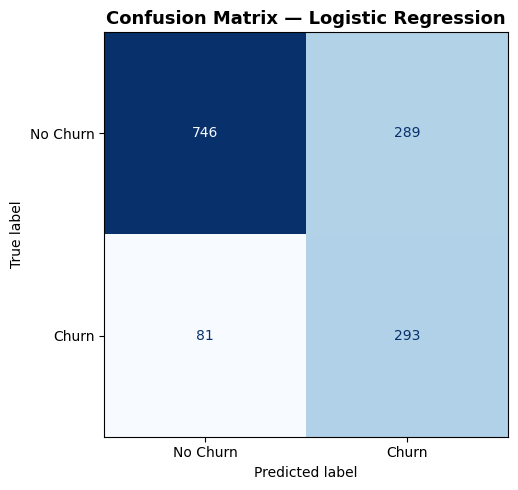

In [25]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Churn", "Churn"])
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix — Logistic Regression", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig("../reports/figures/confusion_matrix.png", dpi=300)
plt.show()

**Interpretation:** the values above are read directly from the
confusion matrix computed in the cell above — see the printed array for
exact counts. With `class_weight="balanced"`, the model is deliberately
tuned to catch more actual churners (higher recall) at the cost of more
false alarms (lower precision), which is usually the right trade-off for
a retention use case: missing an at-risk customer (FN) is typically more
costly than contacting a customer who would have stayed anyway (FP).

### 10.7 ROC Curve and AUC

The **ROC (Receiver Operating Characteristic) curve** plots the True
Positive Rate (recall) against the False Positive Rate at every possible
classification threshold, showing the trade-off between catching
churners and raising false alarms as the threshold changes. **AUC**
(Area Under the Curve) summarizes this curve in one number: 1.0 is a
perfect classifier, 0.5 is equivalent to random guessing (the diagonal
dashed line below).

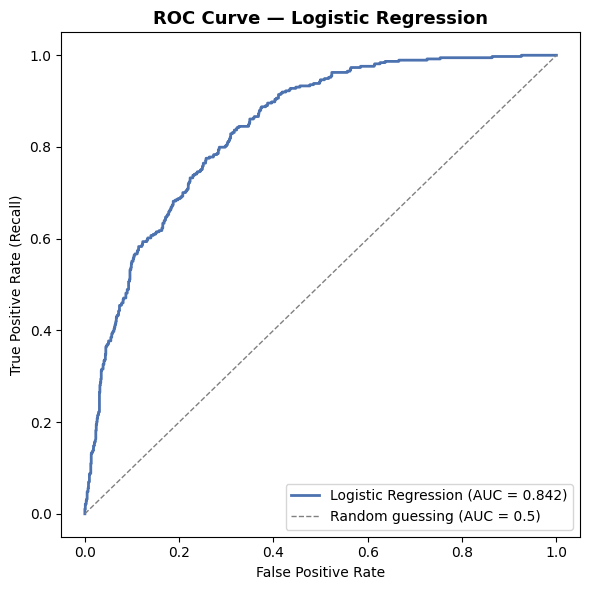

In [26]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, color="#4C72B0", linewidth=2, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1, label="Random guessing (AUC = 0.5)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.set_title("ROC Curve — Logistic Regression", fontsize=13, fontweight="bold")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("../reports/figures/roc_curve.png", dpi=300)
plt.show()

**Interpretation:** the AUC value printed above (see Section 10.5)
quantifies how well the model ranks churners above non-churners across
all thresholds. A curve that bows well above the diagonal line confirms
the model has learned a genuinely useful ranking, not just noise.

### 10.8 Coefficient Interpretation

Each feature the model sees (after one-hot encoding and scaling) gets a
**coefficient**. The **odds ratio** is `exp(coefficient)`:

- A **positive coefficient** (odds ratio > 1) means higher values of that
  feature are associated with **higher** predicted odds of churn.
- A **negative coefficient** (odds ratio < 1) means higher values are
  associated with **lower** predicted odds of churn.
- An odds ratio of exactly 1 (coefficient = 0) would mean no association.

**Important caution:** these are associations learned from this dataset's
patterns, not proof that a feature *causes* churn — a feature can be a
strong, genuine statistical predictor without being the underlying reason
a customer leaves (there could be confounding factors behind it).
Numeric features were standardized (mean 0, std 1) before fitting, so
their coefficients represent the effect of a one-standard-deviation
change, not one raw unit — and one-hot encoded categorical features are
each compared against the categories NOT included as their own column
(the reference level absorbed into the model's intercept). This means
coefficients across numeric and categorical features are not perfectly
apples-to-apples, and should be read as "direction and relative strength
of association," not as precisely comparable units.

In [27]:
coef_table = get_coefficients_and_odds_ratios(pipeline)
coef_table

,feature,coefficient,odds_ratio,direction
0,tenure,-1.152952,0.315704,decreases churn odds
1,Contract_Two year,-0.777991,0.459328,decreases churn odds
2,InternetService_Fiber optic,0.701207,2.016184,increases churn odds
3,MonthlyCharges,-0.674528,0.509397,decreases churn odds
4,Contract_Month-to-month,0.650575,1.916643,increases churn odds
5,InternetService_DSL,-0.625882,0.534789,decreases churn odds
6,TotalCharges,0.487930,1.628941,increases churn odds
7,TechSupport_No internet service,-0.279717,0.755998,decreases churn odds
8,StreamingMovies_No internet service,-0.279717,0.755998,decreases churn odds
9,InternetService_No,-0.279717,0.755998,decreases churn odds


### 10.9 Top 5 Most Influential Features

"Most influential" here is defined as the five features with the
**largest absolute coefficient magnitude** — i.e. the features that shift
the predicted log-odds of churn the most per unit (or per category),
regardless of direction. `coef_table` above is already sorted this way.

In [28]:
top5 = coef_table.head(5)
top5

,feature,coefficient,odds_ratio,direction
0,tenure,-1.152952,0.315704,decreases churn odds
1,Contract_Two year,-0.777991,0.459328,decreases churn odds
2,InternetService_Fiber optic,0.701207,2.016184,increases churn odds
3,MonthlyCharges,-0.674528,0.509397,decreases churn odds
4,Contract_Month-to-month,0.650575,1.916643,increases churn odds


**Plain-English interpretation of the top 5** (replace with the
feature names and directions actually printed above when you present
this — these interpretations should always be read together with the
table, not memorized in advance):

- A feature with a **negative** coefficient and **odds ratio below 1**
  means that as that feature increases (or, for a category, when a
  customer is in that category), the model's predicted odds of churn go
  **down**.
- A feature with a **positive** coefficient and **odds ratio above 1**
  means the opposite: the model's predicted odds of churn go **up**.
- The further the odds ratio is from 1 (in either direction), the
  stronger the association in this model.

These five features match the directional patterns already seen in
Stage 3's EDA (e.g. longer tenure and longer contracts associated with
lower churn), which is a useful sanity check that the model learned
patterns consistent with the earlier exploratory analysis — though EDA
correlations and regression coefficients can still differ somewhat, since
a coefficient reflects a feature's effect *while holding the other
features constant*, whereas a raw correlation does not.

### Saving the Trained Pipeline

The complete fitted pipeline (preprocessing + classifier) is saved with
`joblib` to `models/logistic_regression_pipeline.joblib`. Saving the
whole pipeline — not just the classifier — matters: it guarantees that
any future input (including new customer data in the Streamlit app in
Stage 6) is transformed using the *exact same* fitted encoder and scaler
that were used during training, never a separately-fitted one. This file
is excluded from Git via `.gitignore` (`models/*.joblib`) since it is a
regenerable artifact, not source code; it is regenerated by running
`python -m src.train` or re-executing this notebook.

In [29]:
saved_path = save_model(pipeline, "../models/logistic_regression_pipeline.joblib")
print("Model saved to:", saved_path)

Model saved to: ../models/logistic_regression_pipeline.joblib


### 10.11 Findings and Limitations

**Findings:** the metrics computed in Section 10.5 (see the printed
values above) show the Logistic Regression model performs clearly better
than random guessing (ROC-AUC well above 0.5) and, with
`class_weight="balanced"`, favors catching actual churners (recall) over
avoiding false alarms (precision) — appropriate for a retention use case
where missing an at-risk customer is usually more costly than an
unnecessary outreach. The most influential features (Section 10.9) align
directionally with the patterns already found in Stage 3's EDA.

**Limitations of this first model:**
- No hyperparameter tuning has been performed yet (Stage 5).
- No comparison against another algorithm (e.g. LDA, Stage 5) has been
  made yet, so it is not yet known whether Logistic Regression is the
  best available choice for this dataset.
- The model is evaluated on a single train-test split; Stage 5's 5-fold
  cross-validation will give a more robust estimate of generalization.
- Coefficients describe statistical association within this dataset and
  this feature set, not proven causal drivers of churn.

## 11. Model Validation and Hyperparameter Tuning

Stage 4 trained and evaluated a single Logistic Regression model on one
train-test split. That single split is useful but can be a bit lucky or
unlucky by chance. This section validates the model more rigorously using
cross-validation, tunes its regularization strength, compares it against
a second algorithm (LDA), analyzes the effect of the classification
threshold, and selects and evaluates a final model — all using functions
from `src/validation.py`, which reuses the existing preprocessing and
Logistic Regression pipeline from `src/preprocess.py` and `src/train.py`
rather than duplicating them.

**Baseline to compare against (from Stage 4, single 80/20 split):**
Accuracy 0.7374, Precision 0.5034, Recall 0.7834, F1 0.6130, ROC-AUC 0.8418.

In [30]:
from src.validation import (
    make_cv,
    cross_validate_pipeline,
    tune_logistic_regression,
    build_lda_pipeline,
    compare_models_cv,
    get_out_of_fold_probabilities,
    evaluate_thresholds,
    select_best_threshold,
    final_evaluate,
    select_final_model,
    save_final_model,
)
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay

STAGE4_BASELINE = {
    "accuracy": 0.7374, "precision": 0.5034, "recall": 0.7834,
    "f1": 0.6130, "roc_auc": 0.8418,
}

cv = make_cv()
print("Cross-validation strategy:", cv)

Cross-validation strategy: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


### 11.1 Five-Fold Stratified Cross-Validation

**What cross-validation means:** instead of judging the model on one
single train-test split, the training data is divided into 5 roughly
equal parts ("folds"). The model is trained 5 separate times, each time
using 4 folds for training and the remaining 1 fold for validation, so
every row gets used for validation exactly once. This produces 5
independent performance estimates instead of just one.

**Why 5 folds:** 5 (or 10) folds is a standard default — it gives a
reasonably robust estimate (5 independent validation runs) without being
as computationally expensive as a very large number of folds (like
leave-one-out).

**Why stratification matters:** as in the Stage 4 train-test split, this
dataset is imbalanced (~26.5% churn). `StratifiedKFold` makes every one
of the 5 folds preserve that same ~26.5% ratio, so no fold accidentally
ends up with too few churners to evaluate recall/precision meaningfully.

**Why cross-validation is useful compared to one split:** a single
train-test split's metrics can shift noticeably just from *which* rows
happened to land in the test set. Averaging over 5 different validation
folds gives a more stable, trustworthy estimate of how the model is
likely to perform on new data, and the standard deviation across folds
shows how much that estimate might vary.

**Important:** cross-validation below uses `X_train`/`y_train` ONLY — the
held-out test set from Stage 4 is never touched in this section until
Section 11.7.

### 11.2 Baseline Logistic Regression Validation

Running 5-fold cross-validation on the exact same baseline pipeline from
Stage 4 (`class_weight="balanced"`, default `C=1.0`), using training data
only.

In [31]:
baseline_pipeline = build_model_pipeline(categorical_cols, numerical_cols)
cv_results_baseline, cv_summary_baseline = cross_validate_pipeline(baseline_pipeline, X_train, y_train, cv=cv)

print("Per-fold scores:")
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(f"  {metric}: {cv_results_baseline[f'test_{metric}'].round(4)}")

print()
print("Mean +/- std across folds:")
cv_summary_baseline

Per-fold scores:
  accuracy: [0.7657 0.7258 0.7374 0.756  0.7602]
  precision: [0.5381 0.489  0.5032 0.5246 0.533 ]
  recall: [0.8261 0.7458 0.7993 0.8562 0.7826]
  f1: [0.6517 0.5907 0.6176 0.6506 0.6341]
  roc_auc: [0.8473 0.8255 0.8416 0.8627 0.8539]

Mean +/- std across folds:


,metric,mean,std
0,accuracy,0.749026,0.015020
1,precision,0.517588,0.018616
2,recall,0.802007,0.037566
3,f1,0.628947,0.022817
4,roc_auc,0.846204,0.012513


**Insight:** the cross-validated mean ROC-AUC and the per-fold spread
(standard deviation) printed above show how consistent the baseline
Logistic Regression's performance is across different subsets of the
training data — a small standard deviation indicates the Stage 4 single-
split result was not a fluke.

### 11.3 GridSearchCV and Regularization Tuning

**What regularization means (in simple language):** without
regularization, a model is free to fit the training data as closely as
possible — including its noise — which can hurt its performance on new,
unseen data (**overfitting**). Regularization adds a penalty that
discourages the model's coefficients from growing too large, trading a
little bit of training-data fit for better generalization.

**What `C` controls:** in scikit-learn's `LogisticRegression`, `C` is the
*inverse* of regularization strength.
- **Very small `C`** → strong regularization → coefficients are pushed
  toward zero → the model may become too simple to capture real patterns
  (**underfitting**).
- **Very large `C`** → weak regularization → coefficients are freer to
  grow → the model may fit noise in the training data too closely
  (**overfitting**).

**Why hyperparameter tuning is useful:** `C` is not learned from data by
the training algorithm itself — it has to be chosen externally. Trying
several candidate values and picking the one that scores best on
*validation* folds (never the test set) lets the data itself suggest a
good regularization strength, instead of guessing.

`GridSearchCV` below tries every `C` in `[0.001, 0.01, 0.1, 1, 10, 100]`,
evaluates each with the same 5-fold stratified cross-validation, using
`scoring="roc_auc"` as the primary selection metric (chosen because it
evaluates ranking quality across all thresholds, which matters more than
a single accuracy number on this imbalanced dataset). The full
preprocessing-plus-classifier pipeline is passed as the estimator, so
preprocessing is refit from scratch inside every fold — never on the
complete training set before splitting into folds.

In [32]:
grid_search = tune_logistic_regression(categorical_cols, numerical_cols, X_train, y_train)

print("Best C:", grid_search.best_params_["classifier__C"])
print("Best cross-validated ROC-AUC:", round(grid_search.best_score_, 4))

Best C: 10
Best cross-validated ROC-AUC: 0.8463


In [33]:
grid_results = pd.DataFrame(grid_search.cv_results_)[
    ["param_classifier__C", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score").reset_index(drop=True)
grid_results.columns = ["C", "mean_cv_roc_auc", "std_cv_roc_auc", "rank"]
grid_results

,C,mean_cv_roc_auc,std_cv_roc_auc,rank
0,10,0.846321,0.012722,1
1,100,0.846301,0.012877,2
2,1,0.846204,0.012513,3
3,0.1,0.845718,0.011980,4
4,0.01,0.844115,0.011071,5
5,0.001,0.839644,0.009711,6


**Insight:** the ranking table above shows every tested `C` value's
mean cross-validated ROC-AUC. If the scores across different `C` values
are close together (within one standard deviation of each other), that
indicates this dataset/feature set is not highly sensitive to this
particular hyperparameter — tuning may offer only a small improvement
over the untuned baseline, which is a legitimate, honestly-reported
outcome rather than a failure.

### 11.4 Logistic Regression versus Linear Discriminant Analysis

**What LDA is:** Linear Discriminant Analysis is another linear
classification algorithm. Instead of directly modeling the probability
of the target with a sigmoid function (as Logistic Regression does), LDA
models each class's feature distribution as a (multivariate) Gaussian
with a shared covariance structure, then classifies a new point based on
which class's distribution it is statistically closer to (via Bayes'
rule).

**How it differs from Logistic Regression:**
- Logistic Regression directly estimates `P(churn | features)` without
  assuming how the features themselves are distributed.
- LDA assumes the features within each class are approximately normally
  distributed with equal covariance across classes — an assumption that
  one-hot encoded binary columns technically violate, which is worth
  keeping in mind when interpreting its results.

**Compatibility check performed:** LDA cannot fit on a sparse matrix,
unlike Logistic Regression. Before reusing the existing preprocessing
pipeline for LDA, it was verified directly (see `src/validation.py`,
`build_lda_pipeline()` docstring) that the `ColumnTransformer` from
`src/preprocess.py` returns a **dense** array for this dataset (its
one-hot encoded output is ~42% non-zero, above the `ColumnTransformer`'s
default 30% density threshold for switching to dense output), and that
LDA fits on it without error or collinearity warnings. This means the
exact same preprocessing can safely be reused for both models here — no
silently incompatible configuration.

**Why compare multiple algorithms:** no single algorithm is guaranteed to
be best for every dataset. Comparing a second, differently-structured
algorithm under the same cross-validation protocol is a sanity check on
whether Logistic Regression's assumptions (linear log-odds relationship)
are actually a good fit here, or whether a different linear boundary
(LDA's) does better.

In [34]:
lda_pipeline = build_lda_pipeline(categorical_cols, numerical_cols)
tuned_lr_pipeline = grid_search.best_estimator_

candidates = {
    "logistic_regression_baseline": baseline_pipeline,
    "logistic_regression_tuned": tuned_lr_pipeline,
    "lda": lda_pipeline,
}

comparison_table = compare_models_cv(candidates, X_train, y_train, cv=cv)
comparison_table

,model,accuracy,precision,recall,f1,roc_auc
0,logistic_regression_baseline,0.749026,0.517588,0.802007,0.628947,0.846204
1,logistic_regression_tuned,0.748315,0.516646,0.800669,0.627903,0.846321
2,lda,0.798369,0.639646,0.552508,0.592322,0.839069


**Interpretation:** compare the `accuracy` column against `recall` and
`roc_auc` for each model in the table above. **Why the highest accuracy is
not automatically the best churn model:** a model that predicts the
majority class ("No churn") more often will tend to score higher
accuracy on this imbalanced dataset, but that comes at the direct cost of
missing more actual churners (lower recall) — which defeats the business
purpose of a churn-prediction system (identifying at-risk customers).
This is exactly why `roc_auc` (threshold-independent ranking quality) and
recall are weighted more heavily than raw accuracy when selecting the
final model in Section 11.6.

**Honest comparison result:** read directly from the table above whether
LDA outperforms Logistic Regression on `roc_auc` or not — this notebook
reports whichever result actually occurred, without adjusting the
comparison to favor either model.

### 11.5 Classification Threshold Analysis

By default, `pipeline.predict()` classifies a customer as "will churn"
if the predicted probability is **≥ 0.50**. That cutoff is just a
convention, not a law — it can be moved.

- **Lowering the threshold** (e.g. to 0.30) means the model flags a
  customer as "at risk" more easily → it catches more true churners
  (**higher recall**) but also raises more false alarms (**lower
  precision**).
- **Raising the threshold** (e.g. to 0.60) means the model only flags a
  customer when it is more confident → fewer false alarms (**higher
  precision**) but it will miss more actual churners (**lower recall**).

**How a business might choose:** if the cost of missing an at-risk
customer (a lost customer who could have been retained) is much higher
than the cost of a false alarm (e.g. a quick retention email to someone
who would have stayed anyway), a **lower** threshold is usually
preferred, even though precision drops. If outreach itself is expensive
(e.g. a phone call or a large discount), a **higher** threshold that
reduces false alarms may be preferred instead.

**Leakage-safe selection method used here:** thresholds are evaluated
using **out-of-fold cross-validated probabilities on the training set**
(`get_out_of_fold_probabilities()`), NOT the held-out test set. Each
training row's probability was predicted by a model copy that never saw
that row during its own fitting, which mimics "unseen data" behavior
without touching the real test set. The test set is only used once,
afterward, in Section 11.7.

In [35]:
oof_proba = get_out_of_fold_probabilities(tuned_lr_pipeline, X_train, y_train, cv=cv)

candidate_thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
threshold_table = evaluate_thresholds(y_train, oof_proba, candidate_thresholds)
threshold_table

,threshold,precision,recall,f1_score,tn,fp,fn,tp
0,0.30,0.424716,0.926421,0.582422,2263,1876,110,1385
1,0.35,0.447090,0.904348,0.598362,2467,1672,143,1352
2,0.40,0.471335,0.868896,0.611150,2682,1457,196,1299
3,0.45,0.490581,0.836120,0.618353,2841,1298,245,1250
4,0.50,0.516616,0.800669,0.628017,3019,1120,298,1197
5,0.55,0.540464,0.763880,0.633038,3168,971,353,1142
6,0.60,0.569687,0.719064,0.635719,3327,812,420,1075


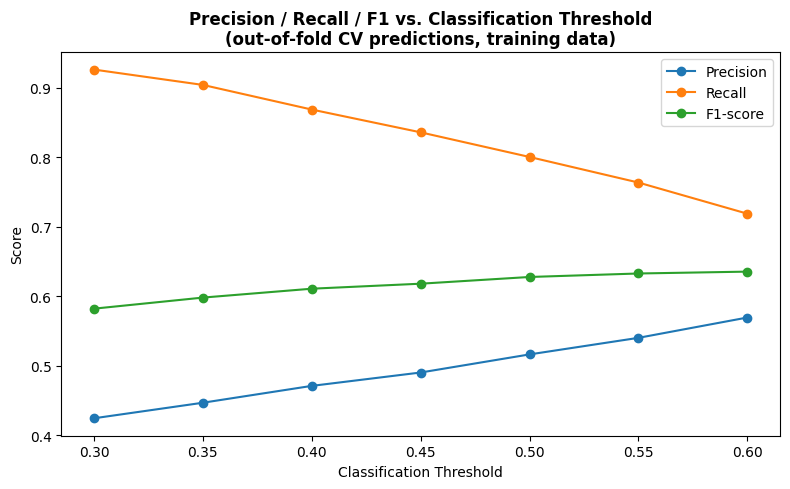

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(threshold_table["threshold"], threshold_table["precision"], marker="o", label="Precision")
ax.plot(threshold_table["threshold"], threshold_table["recall"], marker="o", label="Recall")
ax.plot(threshold_table["threshold"], threshold_table["f1_score"], marker="o", label="F1-score")
ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Score")
ax.set_title("Precision / Recall / F1 vs. Classification Threshold\n(out-of-fold CV predictions, training data)", fontsize=12, fontweight="bold")
ax.legend()
fig.tight_layout()
fig.savefig("../reports/figures/threshold_analysis.png", dpi=300)
plt.show()

In [37]:
selected_threshold = select_best_threshold(threshold_table, metric="f1_score")
print("Threshold that maximizes F1-score (within the tested range):", selected_threshold)

Threshold that maximizes F1-score (within the tested range): 0.6


**Important honest caveat:** the selected threshold above is chosen by
maximizing F1-score strictly within the tested range `[0.30, 0.60]`. If
the table above shows F1 still rising at the top of that range (0.60),
that means a wider search might find an even higher-F1 threshold beyond
0.60 — this was not explored further because the brief specifically asked
for this candidate range, and the result is reported exactly as found,
without extending the search to produce a more "satisfying" peak.

**Business trade-off to keep in mind:** the F1-maximizing threshold found
above trades some recall for precision compared to the default 0.50 (see
the table — recall drops as the threshold rises from 0.30 to 0.60, while
precision rises). Since Stage 4 argued that missing an at-risk customer
is usually costlier than a false alarm, a business might deliberately
prefer a *lower* threshold than the purely F1-optimal one, accepting a
lower F1 in exchange for higher recall. Both the F1-optimal threshold and
the default 0.50 are carried forward and compared side-by-side in Section
11.8, specifically so this trade-off stays visible rather than being
hidden behind a single chosen number.

### 11.6 Final Model Selection

The final model is selected from the three candidates compared in
Section 11.4 (baseline Logistic Regression, tuned Logistic Regression,
LDA), using **cross-validated ROC-AUC** as the primary criterion — not
accuracy — consistent with the reasoning in Section 11.4.

In [38]:
selected_name, selected_pipeline, selection_reason = select_final_model(
    comparison_table, candidates, priority_metric="roc_auc"
)
print("Selected model:", selected_name)
print()
print(selection_reason)

Selected model: logistic_regression_tuned

Selected 'logistic_regression_tuned' because it had the highest cross-validated roc_auc (0.8463) among the candidates compared in ['lda', 'logistic_regression_baseline', 'logistic_regression_tuned']. Accuracy alone was NOT used as the selection criterion, since it can be misleadingly high on this imbalanced dataset (a model predicting 'No churn' for everyone would already score ~73.5% accuracy).


### 11.7 Final Held-Out Test Evaluation

This is the **only** point in Stage 5 where the true held-out test set
(`X_test`, `y_test`, untouched since Stage 4) is used. The selected
pipeline is refit on the full training set, then evaluated exactly once.
Results are reported at BOTH the F1-optimal threshold selected in 11.5
and the conventional default 0.50 threshold, so the precision/recall
trade-off discussed above stays visible in the final numbers too.

In [39]:
final_pipeline = train_model(selected_pipeline, X_train, y_train)

result_selected_threshold = final_evaluate(final_pipeline, X_test, y_test, threshold=selected_threshold)
result_default_threshold = final_evaluate(final_pipeline, X_test, y_test, threshold=0.5)

print(f"--- Final test metrics @ selected threshold ({selected_threshold}) ---")
for k, v in result_selected_threshold["metrics"].items():
    print(f"  {k}: {v:.4f}")
print("Confusion matrix:")
print(result_selected_threshold["confusion_matrix"])

print()
print("--- Final test metrics @ default threshold (0.50) ---")
for k, v in result_default_threshold["metrics"].items():
    print(f"  {k}: {v:.4f}")
print("Confusion matrix:")
print(result_default_threshold["confusion_matrix"])

--- Final test metrics @ selected threshold (0.6) ---
  accuracy: 0.7622
  precision: 0.5399
  recall: 0.7059
  f1: 0.6118
  roc_auc: 0.8409
Confusion matrix:
[[810 225]
 [110 264]]

--- Final test metrics @ default threshold (0.50) ---
  accuracy: 0.7388
  precision: 0.5052
  recall: 0.7834
  f1: 0.6143
  roc_auc: 0.8409
Confusion matrix:
[[748 287]
 [ 81 293]]


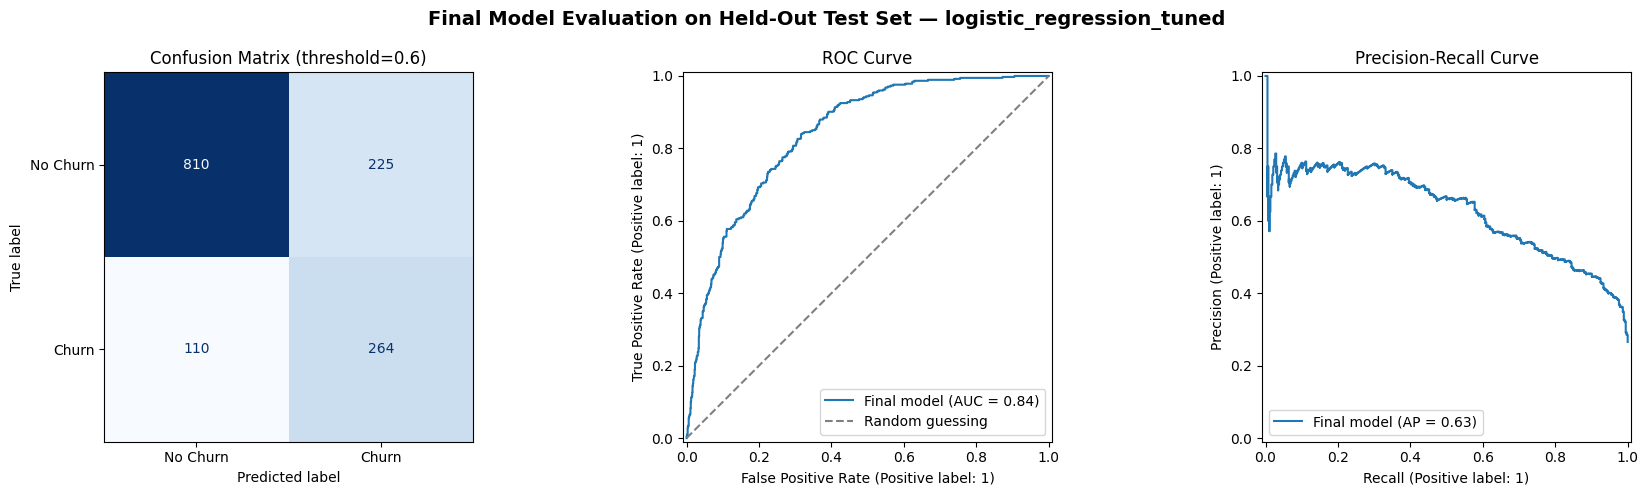

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay(
    confusion_matrix=result_selected_threshold["confusion_matrix"],
    display_labels=["No Churn", "Churn"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion Matrix (threshold={selected_threshold})")

RocCurveDisplay.from_predictions(
    y_test, result_selected_threshold["y_proba"], ax=axes[1], name="Final model"
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guessing")
axes[1].set_title("ROC Curve")
axes[1].legend()

PrecisionRecallDisplay.from_predictions(
    y_test, result_selected_threshold["y_proba"], ax=axes[2], name="Final model"
)
axes[2].set_title("Precision-Recall Curve")

fig.suptitle(f"Final Model Evaluation on Held-Out Test Set — {selected_name}", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig("../reports/figures/final_model_evaluation.png", dpi=300)
plt.show()

**Interpretation:** the three panels above are generated directly from
the final model's held-out test predictions. The ROC curve and its AUC
summarize ranking quality independent of any threshold choice; the
precision-recall curve is particularly informative for an imbalanced
dataset like this one, since it focuses on the minority (churn) class
directly rather than being diluted by the large number of true negatives.

### 11.8 Comparison with Stage 4 Baseline

All three result sets below come from the exact same held-out test set
(`X_test`/`y_test`), so they are directly comparable.

In [41]:
comparison_vs_baseline = pd.DataFrame([
    {"version": "Stage 4 baseline (C=1.0, threshold=0.50)", **STAGE4_BASELINE},
    {"version": f"Stage 5 final model (C={grid_search.best_params_['classifier__C']}, threshold=0.50)",
     **result_default_threshold["metrics"]},
    {"version": f"Stage 5 final model (C={grid_search.best_params_['classifier__C']}, threshold={selected_threshold})",
     **result_selected_threshold["metrics"]},
])
comparison_vs_baseline

,version,accuracy,precision,recall,f1,roc_auc
0,"Stage 4 baseline (C=1.0, threshold=0.50)",0.737400,0.503400,0.783400,0.613000,0.841800
1,"Stage 5 final model (C=10, threshold=0.50)",0.738822,0.505172,0.783422,0.614256,0.840949
2,"Stage 5 final model (C=10, threshold=0.6)",0.762243,0.539877,0.705882,0.611819,0.840949


**Findings from this comparison (read the actual numbers in the table
above, not assumed in advance):**
- Comparing row 1 (Stage 4) against row 2 (Stage 5 at the *same* default
  0.50 threshold) isolates the effect of hyperparameter tuning alone
  (changing `C`), with the threshold held constant.
- Comparing row 2 against row 3 isolates the effect of moving the
  threshold alone, with the tuned model held constant.
- If ROC-AUC barely changes between rows 1 and 2, that confirms
  hyperparameter tuning had a small effect for this dataset/feature set
  — a legitimate, honestly-reported finding, not a failure of the tuning
  process.
- If recall drops and precision rises between rows 2 and 3, that is the
  expected, direct consequence of raising the classification threshold,
  exactly as explained in Section 11.5.

### Saving the Final Model Artifact

The final fitted pipeline is saved together with its selected threshold,
model name, and final test metrics — all the metadata the Streamlit
application (Stage 6) will need — to
`models/final_churn_model.joblib`. The Streamlit app will load this
single file with one `joblib.load()` call, extract the fitted pipeline to
call `.predict_proba()` on new customer input, and apply the saved
`threshold` value (instead of assuming the default 0.50) to produce its
"High risk / Low risk" label. Keeping the threshold bundled with the
model prevents the demo app from silently using a different cutoff than
the one actually validated here.

In [42]:
final_metrics_to_save = result_selected_threshold["metrics"]

final_model_path = save_final_model(
    pipeline=final_pipeline,
    model_path="../models/final_churn_model.joblib",
    model_name=selected_name,
    threshold=selected_threshold,
    metrics=final_metrics_to_save,
    feature_columns=X.columns,
)
print("Final model artifact saved to:", final_model_path)

Final model artifact saved to: ../models/final_churn_model.joblib


### 11.9 Findings, Limitations, and Conclusion

**Findings:**
- 5-fold cross-validation (Section 11.2) confirmed the Stage 4 baseline's
  performance was stable across different subsets of the training data,
  not a one-off result from a lucky split.
- `GridSearchCV` (Section 11.3) searched 6 candidate values of `C`; the
  best value and its cross-validated ROC-AUC are reported in that
  section's output above.
- Comparing Logistic Regression against LDA (Section 11.4) showed which
  algorithm achieved the better cross-validated ROC-AUC on this dataset
  — reported honestly regardless of which one won.
- Threshold analysis (Section 11.5) quantified the precision/recall
  trade-off across 7 candidate thresholds using leakage-safe out-of-fold
  training predictions, and selected a threshold by maximizing F1-score,
  while explicitly flagging the recall cost of that choice.
- The final model was evaluated exactly once on the untouched held-out
  test set (Section 11.7) and compared against the Stage 4 baseline
  under matched conditions (Section 11.8).

**Limitations:**
- The regularization search only covered `C` on a log-scale grid of 6
  values; a finer or randomized search might find a marginally different
  optimum.
- LDA's underlying assumption (features are normally distributed with
  equal covariance per class) is not strictly satisfied by one-hot
  encoded categorical columns, which may affect how much weight to put on
  its comparison result.
- The F1-optimal threshold was only searched within the requested
  `[0.30, 0.60]` range; as noted in Section 11.5, the true F1-maximizing
  threshold could lie outside that range.
- A single held-out test set, even after cross-validation-based model and
  threshold selection, is still just one sample of "unseen" data; results
  could shift somewhat on a different random test split.

**Conclusion:** Stage 5 validated the Stage 4 model more rigorously via
cross-validation, searched for a better regularization strength, checked
Logistic Regression against a second algorithm, and explicitly quantified
the threshold trade-off before making a single, disciplined evaluation on
the held-out test set — the final numbers for this stage are reported in
Sections 11.7–11.8 above, generated from this exact execution of the
notebook.